# 서울시 전월세 가격 요인 분석 · 예산 기반 거주 전략 추천

**목적** — 지역·면적·연식에 따른 전월세 가격 구조를 파악하고, 예측가격으로 예산에 맞는 거주 지역과 전략(월세 vs 전세)을 비교

| 항목 | 내용 |
|---|---|
| 데이터 | 국토교통부 실거래가 공개시스템 — 서울 전월세 2023~2025 (아파트 · 오피스텔 · 연립다세대 · 단독다가구) |
| 규모 | 원천 약 193만 건 → 정제 후 약 181만 건, 25개 자치구 · 405개 구-법정동 조합 |
| 모델 | 선형회귀(기준) vs LightGBM — 월세 · 월세 보증금 · 전세 보증금 |
| 산출물 | Power BI 4페이지 의사결정 대시보드용 예측 데이터 |

In [6]:
from google.colab import drive
drive.mount('/content/drive')

%cd "/content/drive/MyDrive/데이터분석_포트폴리오/seoul-rent-price-analysis/notebooks"
!ls ../data | head
!pip install -q -r ../requirements.txt
!apt-get -qq install fonts-nanum > /dev/null

import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/데이터분석_포트폴리오/seoul-rent-price-analysis/notebooks
단독다가구(전월세)_실거래가_2023.csv
단독다가구(전월세)_실거래가_2024.csv
단독다가구(전월세)_실거래가_2025.csv
서울시 상권분석서비스(영역-행정동).csv
서울시 행정동 좌표.xlsx
아파트(전월세)_실거래가_2023.csv
아파트(전월세)_실거래가_2024.csv
아파트(전월세)_실거래가_2025.csv
연립다세대(전월세)_실거래가_2023.csv
연립다세대(전월세)_실거래가_2024.csv


In [7]:
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

DATA_DIR = "../data"              # 국토교통부 실거래가 원본 CSV · 행정동 좌표
OUT_DIR = "../data/processed"     # Power BI용 결과 CSV
IMG_DIR = "../images"             # 차트 저장 위치
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)

## 1. 데이터 불러오기 · 통합

In [8]:
# 국토교통부 실거래가 공개시스템 CSV (주택유형 4종 × 2023~2025년)
# 파일 상단 15줄은 안내문이라 skiprows=15
YEARS = [2023, 2024, 2025]


def load_type(file_prefix):
    frames = [pd.read_csv(f"{DATA_DIR}/{file_prefix}_{y}.csv", encoding="cp949", sep=",", skiprows=15)
              for y in YEARS]
    return pd.concat(frames, ignore_index=True)


apt = load_type("아파트(전월세)_실거래가")
officetel = load_type("오피스텔(전월세)_실거래가")
villa = load_type("연립다세대(전월세)_실거래가")
house = load_type("단독다가구(전월세)_실거래가")

for name, d in [("아파트", apt), ("오피스텔", officetel), ("연립다세대", villa), ("단독다가구", house)]:
    print(f"{name}: {len(d):,}건")

아파트: 806,205건
오피스텔: 251,505건
연립다세대: 418,162건
단독다가구: 451,030건


In [9]:
# 컬럼명 표준화 · 필요한 컬럼만 추출 · 데이터 타입 변환
COLS = ["시군구", "주택유형", "전월세구분", "면적", "보증금", "월세", "건축년도", "층", "계약년월"]


def standardize(d, area_col, housing_type=None, has_floor=True):
    d = d.rename(columns={area_col: "면적", "보증금(만원)": "보증금", "월세금(만원)": "월세"})
    if not has_floor:
        d["층"] = None               # 단독다가구는 층 정보 없음
    if housing_type:
        d["주택유형"] = housing_type  # 오피스텔 원본에는 주택유형 컬럼이 없음
    d = d[COLS].copy()
    for col in ["보증금", "월세"]:   # "1,200" 같은 문자열 → 숫자
        d[col] = pd.to_numeric(d[col].astype(str).str.replace(",", ""), errors="coerce")
    d["계약년월"] = pd.to_datetime(d["계약년월"].astype(str), format="%Y%m")
    return d


df = pd.concat([
    standardize(apt, "전용면적(㎡)"),
    standardize(officetel, "전용면적(㎡)", housing_type="오피스텔"),
    standardize(villa, "전용면적(㎡)"),
    standardize(house, "계약면적(㎡)", has_floor=False),
], ignore_index=True)

print(f"원천 거래: {len(df):,}건")

원천 거래: 1,926,902건


## 2. 정제 · 파생변수

In [10]:
# 정제 · 파생변수
df = df[(df["건축년도"] >= 1900) & (df["건축년도"] <= 2025)]   # 비정상 건축년도 제거
df["층"] = pd.to_numeric(df["층"], errors="coerce")

df["계약연도"] = df["계약년월"].dt.year
df["계약월"] = df["계약년월"].dt.month
df["계약분기"] = df["계약년월"].dt.quarter
df["건물나이"] = df["계약연도"] - df["건축년도"]


def age_group(age):
    if age < 5:
        return "신축"
    elif age < 15:
        return "준신축"
    elif age < 30:
        return "중간"
    return "노후"


df["건물나이구간"] = df["건물나이"].apply(age_group)
df["월세"] = df["월세"].fillna(0)
df[["시", "구", "동"]] = df["시군구"].str.split(" ", expand=True)

# 면적당 가격 (※ 컬럼명은 Power BI 호환을 위해 유지 — 실제 단위는 '㎡당 만 원')
df["평당보증금"] = df["보증금"] / df["면적"]
df["평당월세"] = df["월세"] / df["면적"]

df = df[["시군구", "시", "구", "동", "주택유형", "전월세구분",
         "면적", "보증금", "월세", "평당보증금", "평당월세",
         "건축년도", "건물나이", "건물나이구간", "층",
         "계약년월", "계약연도", "계약월", "계약분기"]]

In [11]:
# 이상치 · 범위 제한
df = df[df["평당보증금"] < df["평당보증금"].quantile(0.99)]   # 면적당 보증금 상위 1% 제거
df = df[df["평당월세"] < df["평당월세"].quantile(0.99)]       # 면적당 월세 상위 1% 제거
df = df[(df["면적"] >= 10) & (df["면적"] <= 200)]              # 전용면적 10~200㎡

# 환산월세: 전세·월세를 하나의 가격으로 비교하기 위한 지표
# 보증금 100만 원 = 월세 1만 원으로 환산 (연 12% 전환율 가정, 비교용 지표)
df["환산월세"] = df["월세"] + (df["보증금"] / 100)

# 층 결측(단독다가구) → -1로 채우고 층 유무 변수로 구분
df["층_유무"] = df["층"].notnull().astype(int)
df["층"] = df["층"].fillna(-1)

# 임대유형: 전월세구분이 '월세'라도 월세가 5만 원 이하면 준전세로 분류
df["임대유형"] = "월세"
df.loc[df["전월세구분"] == "전세", "임대유형"] = "전세"
df.loc[(df["전월세구분"] == "월세") & (df["월세"] <= 5), "임대유형"] = "준전세"

print(f"정제 후: {len(df):,}건")

정제 후: 1,839,499건


In [12]:
# 면적구간 · 층구간
df["면적구간"] = pd.cut(df["면적"], bins=[0, 20, 40, 60, 85, 120, 200],
                    labels=["초소형(~20㎡/~6평)", "소형(20~40㎡/6~12평)", "중소형(40~60㎡/12~18평)",
                            "중형(60~85㎡/18~26평)", "대형(85~120㎡/26~36평)", "초대형(120㎡~/36평~)"])

# 층 -1, -2 … 는 지하층 / 단독다가구(층_유무 = 0)는 층구간에서 제외
df["층구간"] = pd.cut(df["층"], bins=[-10, 0, 1, 3, 10, 20, 100],
                   labels=["지하", "1층", "저층(2~3층)", "중층(4~10층)", "고층(11~20층)", "초고층(21층~)"])
df.loc[df["층_유무"] == 0, "층구간"] = np.nan

# 같은 구·동 안에서의 상대 가격 등급 (환산월세 기준 하위 25% 저가 / 상위 25% 고가)
df["가격지표"] = df["환산월세"]
grouped = df.groupby(["구", "동"])["가격지표"]
q1 = grouped.transform(lambda x: x.quantile(0.25))
q3 = grouped.transform(lambda x: x.quantile(0.75))
df["가격등급"] = np.where(df["가격지표"] < q1, "저가", np.where(df["가격지표"] > q3, "고가", "평균"))

## 3. 탐색적 분석

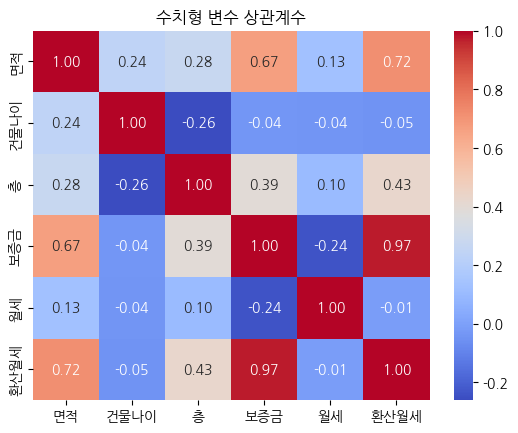

[면적구간별 평균 환산월세 (만 원)]
면적구간
초소형(~20㎡/~6평)          86.0
소형(20~40㎡/6~12평)      136.0
중소형(40~60㎡/12~18평)    265.0
중형(60~85㎡/18~26평)     470.0
대형(85~120㎡/26~36평)    618.0
초대형(120㎡~/36평~)       819.0
Name: 환산월세, dtype: float64

[층구간별 평균 환산월세 (만 원)]
층구간
지하            103.0
1층            294.0
저층(2~3층)      243.0
중층(4~10층)     297.0
고층(11~20층)    391.0
초고층(21층~)     593.0
Name: 환산월세, dtype: float64

[월별 거래 건수]
계약월
1     159516
2     174664
3     169566
4     148394
5     153120
6     152376
7     151737
8     146323
9     132506
10    143028
11    144793
12    163476
Name: count, dtype: int64


In [13]:
# 가격 요인 탐색
num_cols = ["면적", "건물나이", "층", "보증금", "월세", "환산월세"]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("수치형 변수 상관계수")
plt.show()

print("[면적구간별 평균 환산월세 (만 원)]")
print(df.groupby("면적구간")["환산월세"].mean().round(0))
print("\n[층구간별 평균 환산월세 (만 원)]")
print(df.groupby("층구간")["환산월세"].mean().round(0))
print("\n[월별 거래 건수]")
print(df["계약월"].value_counts().sort_index())

## 4. 행정동 좌표 결합

In [14]:
# 행정동 좌표 결합
# 좌표 파일은 행정동(역삼1동·역삼2동 …) 단위 → 법정동(역삼동)으로 이름을 맞춘 뒤
# (구, 동) 기준 평균 좌표로 결합 (같은 이름 행정동이 여러 개라 그대로 merge하면 거래가 복제됨)
coord = pd.read_excel(f"{DATA_DIR}/서울시 행정동 좌표.xlsx")
coord = coord.rename(columns={"sido": "시", "gu": "구", "dong": "동", "lat": "위도", "lng": "경도"})


def simplify_dong(x):
    x = re.sub(r"제?\d+([·.,]\d+)*동$", "동", x)   # 역삼1동 · 면목제2동 · 면목3·8동 → 역삼동 · 면목동
    return re.sub(r"\s", "", x)


coord["동_정리"] = coord["동"].apply(simplify_dong)
df["동_정리"] = df["동"]
df.loc[df["동"] == "상도1동", "동_정리"] = "상도동"   # 실거래 데이터에 행정동으로 남은 예외

print("좌표 파일에 없는 동:", set(df["동_정리"]) - set(coord["동_정리"]))

coord_dong = coord.groupby(["구", "동_정리"], as_index=False)[["위도", "경도"]].mean()
rows_before = len(df)
df = df.merge(coord_dong, on=["구", "동_정리"], how="left", validate="many_to_one")
assert len(df) == rows_before, "좌표가 중복 결합되어 행 수가 바뀌었습니다."

print(f"좌표 결합 후 행 수: {len(df):,} / 좌표 결측률: {df['위도'].isnull().mean():.2%}")

좌표 파일에 없는 동: set()
좌표 결합 후 행 수: 1,839,499 / 좌표 결측률: 0.00%


## 5. 가격 예측 모델링

In [15]:
# 모델링용 변수
df["강남여부"] = df["구"].isin(["강남구", "서초구", "송파구"])   # 강남 3구
df["log_환산월세"] = np.log1p(df["환산월세"])

# 환산월세 상·하위 1% 제거
q01, q99 = df["환산월세"].quantile([0.01, 0.99])
df = df[(df["환산월세"] >= q01) & (df["환산월세"] <= q99)]

# 강남역까지 거리 (위경도 좌표 차이 기반 — 상대 비교용 지표)
GANGNAM_LAT, GANGNAM_LNG = 37.498095, 127.027610


def calc_distance(lat, lng):
    return np.sqrt((lat - GANGNAM_LAT) ** 2 + (lng - GANGNAM_LNG) ** 2)


df["강남거리"] = calc_distance(df["위도"], df["경도"])
print(f"분석 대상: {len(df):,}건 / 구·동 조합 {df.groupby(['구', '동_정리']).ngroups}개")

분석 대상: 1,807,361건 / 구·동 조합 405개


In [16]:
# 월세(월세 > 0, 준전세 포함) / 전세(월세 = 0) 분리 · 로그 타깃
rent_df = df[df["월세"] > 0].copy()
year_df = df[df["월세"] == 0].copy()

for d in (rent_df, year_df):
    d["log_보증금"] = np.log1p(d["보증금"])
    d["log_월세"] = np.log1p(d["월세"])

features = ["면적", "건물나이", "층", "위도", "경도", "강남여부", "강남거리", "구", "동_정리", "주택유형"]
cate_cols = ["구", "동_정리", "강남여부", "주택유형"]
for col in cate_cols:
    rent_df[col] = rent_df[col].astype("category")
    year_df[col] = year_df[col].astype("category")

print(f"월세 {len(rent_df):,}건 / 전세 {len(year_df):,}건")

월세 1,021,636건 / 전세 785,725건


In [18]:
# LightGBM 모델 3종 — 월세 · 월세 보증금 · 전세 보증금 (로그 타깃, 학습:검증 = 8:2)
def train_lgbm(data, target):
    X_tr, X_te, y_tr, y_te = train_test_split(data[features], data[target], test_size=0.2, random_state=42)
    model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1)
    model.fit(X_tr, y_tr)
    return model, (X_tr, X_te, y_tr, y_te)


model_rent, split_rent = train_lgbm(rent_df, "log_월세")
model_dep_rent, split_dep = train_lgbm(rent_df, "log_보증금")
model_year, split_year = train_lgbm(year_df, "log_보증금")


def inverse_log(x):
    return np.expm1(x)

In [19]:
# 모델 성능 비교 — 선형회귀(기준) vs LightGBM, 원 단위로 복원한 R² · MAE · RMSE · 오차율
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

num_cols = ['면적', '건물나이', '층', '위도', '경도', '강남거리']
cat_cols = ['구', '동_정리', '강남여부', '주택유형']

def make_linear():
    pre = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ])
    return make_pipeline(pre, LinearRegression())

def to_str(X):
    X = X.copy()
    for c in cat_cols:
        X[c] = X[c].astype(str)
    return X

def scores(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(y_pred_log)
    mask = yt > 0
    return {
        'R²': r2_score(yt, yp),
        'MAE(만 원)': mean_absolute_error(yt, yp),
        'RMSE(만 원)': np.sqrt(mean_squared_error(yt, yp)),
        '오차율 중앙값(%)': np.median(np.abs(yp[mask] - yt[mask]) / yt[mask]) * 100,
    }

tasks = {
    '월세':        (*split_rent, model_rent),
    '월세 보증금': (*split_dep,  model_dep_rent),
    '전세':        (*split_year, model_year),
}

rows = []
for name, (Xtr, Xte, ytr, yte, lgb_model) in tasks.items():
    lin = make_linear().fit(to_str(Xtr), ytr)
    rows.append({'타깃': name, '모델': 'Linear Regression', **scores(yte, lin.predict(to_str(Xte)))})
    rows.append({'타깃': name, '모델': 'LightGBM',          **scores(yte, lgb_model.predict(Xte))})

perf = pd.DataFrame(rows).round(2)
print(perf.to_string(index=False))

    타깃                모델   R²  MAE(만 원)  RMSE(만 원)  오차율 중앙값(%)
    월세 Linear Regression 0.35     31.78      50.46       35.81
    월세          LightGBM 0.54     27.43      42.65       31.49
월세 보증금 Linear Regression 0.31   6294.39   11846.76       67.59
월세 보증금          LightGBM 0.50   5550.82   10072.59       60.23
    전세 Linear Regression 0.75   7632.60   11829.49       16.55
    전세          LightGBM 0.90   4976.00    7428.10       10.77


              월세  월세 보증금    전세
면적          46.3    35.3  58.6
동_정리        28.7    15.2  11.5
주택유형        12.1    32.1  12.1
건물나이         5.4     8.6   6.1
구            3.8     1.8   3.7
층            1.7     6.6   7.4
강남거리         1.7     0.1   0.5
위도           0.2     0.1   0.1
경도           0.2     0.2   0.0
강남여부         0.0     0.0   0.0
(위치 변수 합계)  34.6    17.4  15.8


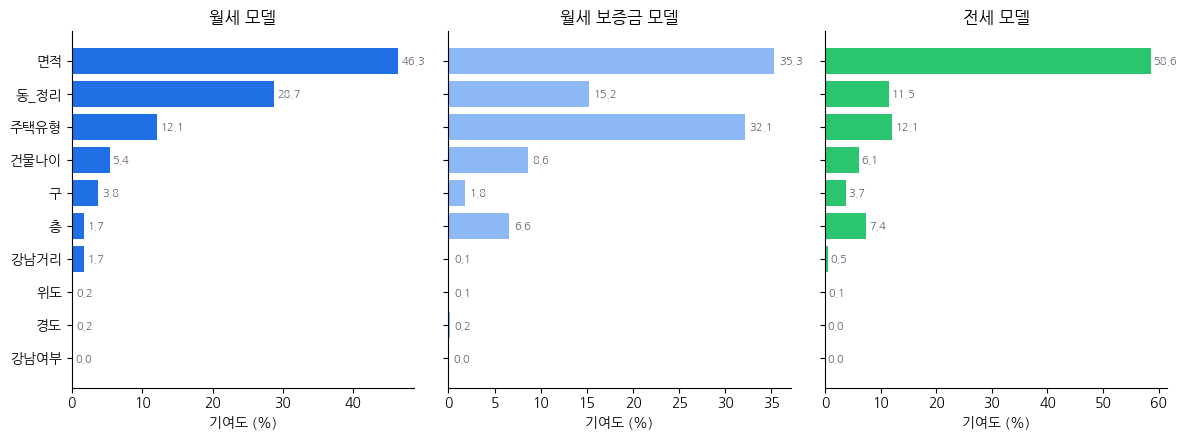

In [20]:
# 변수 중요도 (gain 기준, 모델별 합계 100%)
models = {'월세': model_rent, '월세 보증금': model_dep_rent, '전세': model_year}

imp_all = pd.DataFrame({
    name: m.booster_.feature_importance(importance_type='gain')
    for name, m in models.items()
}, index=features)
imp_all = (imp_all / imp_all.sum() * 100).round(1)          # 모델별 합계 100%
imp_all = imp_all.sort_values('월세', ascending=False)

# 위치 변수 합계 (동·구·좌표·강남거리·강남여부)
loc_cols = ['동_정리', '구', '위도', '경도', '강남거리', '강남여부']
imp_all.loc['(위치 변수 합계)'] = imp_all.loc[loc_cols].sum()
print(imp_all.to_string())

# 그래프
plot_df = imp_all.drop('(위치 변수 합계)').iloc[::-1]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)
for ax, (name, color) in zip(axes, [('월세', '#1F6FE5'), ('월세 보증금', '#8DB8F6'), ('전세', '#2CC56F')]):
    ax.barh(plot_df.index, plot_df[name], color=color)
    for y, v in enumerate(plot_df[name]):
        ax.text(v + 0.5, y, f'{v:.1f}', va='center', fontsize=8, color='#5F6672')
    ax.set_title(f'{name} 모델', fontsize=12)
    ax.set_xlabel('기여도 (%)')
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/feature_importance_3models.png', dpi=200)
plt.show()

## 6. 활용 — 예상 가격 · 예산 적합성 · 매물 적정성

In [21]:
# 조건별 예상 가격
def predict_price(구, 동, 면적, 건물나이, 층, 주택유형):
    sample = pd.DataFrame({"구": [구], "동_정리": [동], "면적": [면적],
                           "건물나이": [건물나이], "층": [층], "주택유형": [주택유형]})
    sample = sample.merge(coord_dong, on=["구", "동_정리"], how="left")
    if sample["위도"].isnull().any():
        raise ValueError("해당 동의 좌표가 없습니다.")
    sample["강남여부"] = sample["구"].isin(["강남구", "서초구", "송파구"])
    sample["강남거리"] = calc_distance(sample["위도"], sample["경도"])
    for col in cate_cols:
        sample[col] = pd.Categorical(sample[col], categories=rent_df[col].cat.categories)
    sample = sample[features]

    rent = inverse_log(model_rent.predict(sample))[0]
    dep = inverse_log(model_dep_rent.predict(sample))[0]
    year = inverse_log(model_year.predict(sample))[0]
    return rent, dep, year


# 2년 실주거비 비교
#   월세 = 월세 × 24개월 + 보증금 기회비용 / 전세 = 보증금 기회비용 (연 4% 가정)
def housing_cost(rent, dep, year, years=2, interest_rate=0.04):
    rent_cost = rent * 12 * years + dep * interest_rate * years
    jeonse_cost = year * interest_rate * years
    return rent_cost, jeonse_cost


# 예산 적합성 판단 → 거주 전략 추천 (예산 충족 여부 우선, 둘 다 가능하면 2년 비용 비교)
def final_decision(구, 동, 면적, 건물나이, 층, 주택유형, budget_rent, budget_dep, years=2, interest_rate=0.04):
    rent, dep, year = predict_price(구, 동, 면적, 건물나이, 층, 주택유형)
    rent_ok = (rent <= budget_rent) and (dep <= budget_dep)
    year_ok = year <= budget_dep
    rent_cost, jeonse_cost = housing_cost(rent, dep, year, years, interest_rate)

    if rent_ok and year_ok:
        strategy = "전세 추천" if jeonse_cost < rent_cost else "월세 추천"
    elif rent_ok:
        strategy = "월세 추천"
    elif year_ok:
        strategy = "전세 추천"
    else:
        strategy = "예산 재검토 필요"

    result = {
        "예상 월세(만 원)": round(rent, 1), "예상 월세보증금(만 원)": round(dep),
        "예상 전세보증금(만 원)": round(year),
        "월세 가능": rent_ok, "전세 가능": year_ok,
        f"{years}년 월세 비용(만 원)": round(rent_cost), f"{years}년 전세 비용(만 원)": round(jeonse_cost),
        "추천 전략": strategy,
    }
    return pd.Series(result)


final_decision("마포구", "망원동", 면적=30, 건물나이=5, 층=3, 주택유형="아파트",
               budget_rent=60, budget_dep=10000)

,0
예상 월세(만 원),50.2
예상 월세보증금(만 원),8890
예상 전세보증금(만 원),30366
월세 가능,True
전세 가능,False
2년 월세 비용(만 원),1916
2년 전세 비용(만 원),2429
추천 전략,월세 추천


In [22]:
# 실제 매물 가격이 예측가 대비 적정한지 평가
def _judge(actual, predicted):
    ratio = (actual - predicted) / predicted
    if ratio < -0.2:
        status = "저평가 (꿀매물)"
    elif ratio < -0.05:
        status = "약간 저렴"
    elif ratio < 0.05:
        status = "적정 가격"
    else:
        status = "비싼 매물"
    return {"예측": round(predicted, 1), "실제": actual, "차이율(%)": round(ratio * 100, 1), "평가": status}


def evaluate_property(구, 동, 면적, 건물나이, 층, 주택유형, 실제월세=None, 실제보증금=None, 실제전세=None):
    pred_rent, pred_dep, pred_year = predict_price(구, 동, 면적, 건물나이, 층, 주택유형)
    result = {}
    if 실제월세 is not None:
        result["월세"] = _judge(실제월세, pred_rent)
    if 실제보증금 is not None:
        result["월세 보증금"] = _judge(실제보증금, pred_dep)
    if 실제전세 is not None:
        result["전세"] = _judge(실제전세, pred_year)
    return pd.DataFrame(result).T


evaluate_property("마포구", "망원동", 30, 5, 3, "아파트", 실제월세=50, 실제보증금=5000)

,예측,실제,차이율(%),평가
월세,50.2,50,-0.4,적정 가격
월세 보증금,8889.8,5000,-43.8,저평가 (꿀매물)


## 7. 대시보드용 데이터 저장

In [23]:
# 대시보드용 예측 결과 저장
# 잔차 = 실제 월세 - 예측 월세 (음수 = 예측보다 저렴하게 거래)
rent_df_export = rent_df.copy()
rent_df_export["pred_월세"] = inverse_log(model_rent.predict(rent_df[features]))
rent_df_export["pred_보증금"] = inverse_log(model_dep_rent.predict(rent_df[features]))
rent_df_export["잔차"] = rent_df_export["월세"] - rent_df_export["pred_월세"]

year_df_export = year_df.copy()
year_df_export["pred_전세"] = inverse_log(model_year.predict(year_df[features]))

area_summary = (rent_df_export.groupby(["구", "동_정리"])
                .agg({"pred_월세": "mean", "pred_보증금": "mean", "면적": "mean", "층": "mean"})
                .reset_index())
year_summary = year_df_export.groupby(["구", "동_정리"]).agg({"pred_전세": "mean"}).reset_index()

RENT_COLS = ["시군구", "시", "구", "동", "주택유형", "전월세구분", "면적", "보증금", "월세",
             "평당보증금", "평당월세", "건축년도", "건물나이", "건물나이구간", "층", "계약년월",
             "계약연도", "계약월", "계약분기", "환산월세", "층_유무", "임대유형", "면적구간",
             "층구간", "가격지표", "가격등급", "동_정리", "위도", "경도", "강남여부",
             "log_환산월세", "강남거리", "log_보증금", "log_월세", "pred_월세", "잔차", "pred_보증금"]
YEAR_COLS = RENT_COLS[:34] + ["pred_전세"]

for name, data, cols in [("rent", rent_df_export, RENT_COLS), ("year", year_df_export, YEAR_COLS)]:
    missing = set(cols) - set(data.columns)
    assert not missing, f"{name}: 없는 열 {missing}"

rent_df_export[RENT_COLS].to_csv(f"{OUT_DIR}/rent_predictions.csv", index=False, encoding="utf-8-sig")
year_df_export[YEAR_COLS].to_csv(f"{OUT_DIR}/year_predictions.csv", index=False, encoding="utf-8-sig")
area_summary.to_csv(f"{OUT_DIR}/area_summary.csv", index=False, encoding="utf-8-sig")
year_summary.to_csv(f"{OUT_DIR}/year_summary.csv", index=False, encoding="utf-8-sig")

# Power BI 속도 개선용 월세 표본 20만 건
rent_df_export.sample(200_000, random_state=42).to_csv(f"{OUT_DIR}/rent_sample.csv", index=False, encoding="utf-8-sig")
print(f"저장 완료: 월세 {len(rent_df_export):,}행 / 전세 {len(year_df_export):,}행")

저장 완료: 월세 1,021,636행 / 전세 785,725행


## 8. 포트폴리오 수치 · 차트

In [24]:
# 수치 요약
print("■ 분석 대상 행 수")
print(f"  전체 {len(df):,} / 월세 {len(rent_df):,} / 전세 {len(year_df):,}")
print(f"  동 개수: {df.groupby(['구', '동_정리']).ngroups}")

print("\n■ 주택유형별 임대유형 비중 (%)")
print((pd.crosstab(df['주택유형'], df['임대유형'], normalize='index') * 100).round(1))

print("\n■ 건물나이구간별 환산월세 중앙값 (만 원)")
print(df.groupby('건물나이구간')['환산월세'].median().round(0))

print("\n■ 층구간별 환산월세 평균 (만 원)")
print(df.groupby('층구간')['환산월세'].mean().round(0))

■ 분석 대상 행 수
  전체 1,807,361 / 월세 1,021,636 / 전세 785,725
  동 개수: 405

■ 주택유형별 임대유형 비중 (%)
임대유형     월세    전세  준전세
주택유형                  
단독다가구  76.9  22.5  0.7
아파트    42.2  57.2  0.6
연립다세대  51.8  46.0  2.2
오피스텔   67.1  30.8  2.2

■ 건물나이구간별 환산월세 중앙값 (만 원)
건물나이구간
노후     135.0
신축     208.0
준신축    155.0
중간     220.0
Name: 환산월세, dtype: float64

■ 층구간별 환산월세 평균 (만 원)
층구간
지하            103.0
1층            288.0
저층(2~3층)      239.0
중층(4~10층)     288.0
고층(11~20층)    373.0
초고층(21층~)     526.0
Name: 환산월세, dtype: float64


In [25]:
# 차트 공통 스타일
BLUE, GREEN, LIGHT, GRAY = '#1F6FE5', '#2CC56F', '#A9C7F5', '#5F6672'

def clean(ax):
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.spines['left'].set_color('#CBD2DB')
    ax.spines['bottom'].set_color('#CBD2DB')
    ax.tick_params(colors=GRAY)

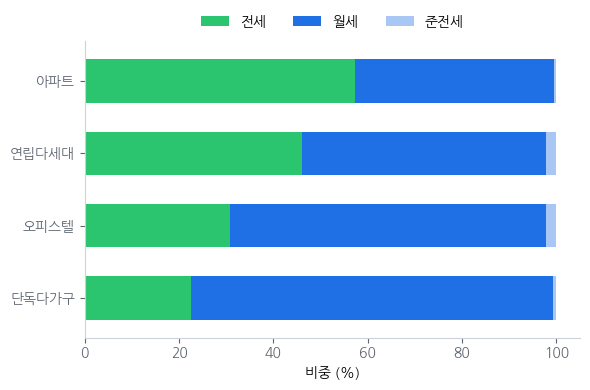

In [26]:
# ① 주택유형별 임대유형 비중 (100% 누적 막대)
ratio = pd.crosstab(df['주택유형'], df['임대유형'], normalize='index')[['전세', '월세', '준전세']] * 100
ratio = ratio.loc[['아파트', '연립다세대', '오피스텔', '단독다가구']]
fig, ax = plt.subplots(figsize=(6, 4))
ratio.plot.barh(stacked=True, color=[GREEN, BLUE, LIGHT], ax=ax, width=0.6)
ax.invert_yaxis()
ax.set_xlabel('비중 (%)'); ax.set_ylabel('')
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0))
clean(ax); plt.tight_layout()
plt.savefig(f'{IMG_DIR}/chart_1_type_ratio.png', dpi=200); plt.show()

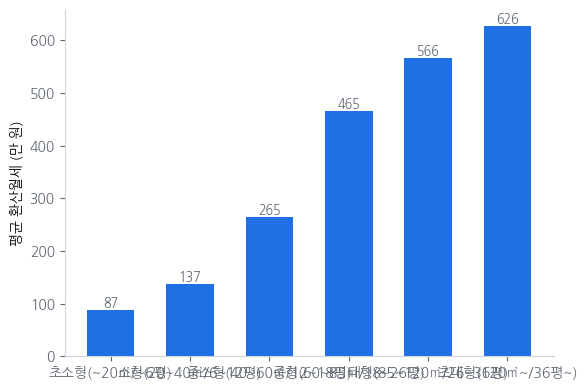

In [27]:
# ② 면적구간별 평균 환산월세
area = df.groupby('면적구간')['환산월세'].mean()
area.index = [str(i).split(' (')[0] for i in area.index]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(area.index, area.values, color=BLUE, width=0.6)
ax.bar_label(bars, fmt='%.0f', color=GRAY, fontsize=9)
ax.set_ylabel('평균 환산월세 (만 원)')
clean(ax); plt.tight_layout()
plt.savefig(f'{IMG_DIR}/chart_2_area_price.png', dpi=200); plt.show()

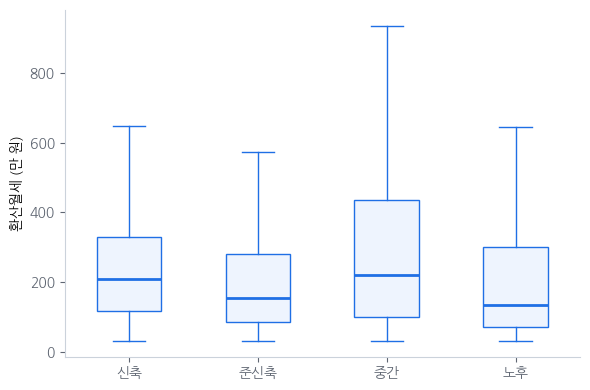

In [28]:
# ③ 건물나이구간별 환산월세 분포 (박스플롯, 이상치 숨김)
order = ['신축', '준신축', '중간', '노후']
data = [df.loc[df['건물나이구간'] == g, '환산월세'].dropna() for g in order]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.5,
           boxprops=dict(facecolor='#EEF4FE', color=BLUE),
           medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order)
ax.set_ylabel('환산월세 (만 원)')
clean(ax); plt.tight_layout()
plt.savefig(f'{IMG_DIR}/chart_3_age_price.png', dpi=200); plt.show()

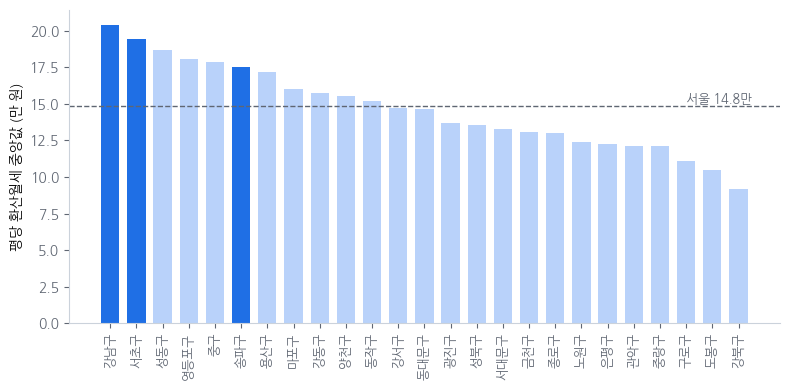

구
강남구     20.4
서초구     19.4
성동구     18.7
영등포구    18.0
중구      17.8
송파구     17.5
용산구     17.2
마포구     16.0
강동구     15.7
양천구     15.5
동작구     15.2
강서구     14.7
동대문구    14.7
광진구     13.7
성북구     13.6
서대문구    13.3
금천구     13.1
종로구     13.0
노원구     12.4
은평구     12.3
관악구     12.1
중랑구     12.1
구로구     11.1
도봉구     10.5
강북구      9.2

최고 강남구 20.4만 / 최저 강북구 9.2만 → 2.2배


In [29]:
# ④ 구별 평당(3.3㎡) 환산월세 — 면적 차이를 걷어낸 순수 위치 효과
BLUE, PALE, GRAY = '#1F6FE5', '#B9D2FA', '#5F6672'

tmp = df[df['면적'] > 0].copy()
tmp['평당_환산월세'] = tmp['환산월세'] / (tmp['면적'] / 3.3)
gu = tmp.groupby('구')['평당_환산월세'].median().sort_values(ascending=False)
seoul = tmp['평당_환산월세'].median()

colors = [BLUE if g in ['강남구', '서초구', '송파구'] else PALE for g in gu.index]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(gu.index, gu.values, color=colors, width=0.7)
ax.axhline(seoul, color=GRAY, linestyle='--', linewidth=1)
ax.text(len(gu) - 0.5, seoul, f' 서울 {seoul:.1f}만', color=GRAY, va='bottom', ha='right', fontsize=9)
ax.set_ylabel('평당 환산월세 중앙값 (만 원)')
ax.tick_params(axis='x', rotation=90, labelsize=9)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
for s in ['left', 'bottom']:
    ax.spines[s].set_color('#CBD2DB')
ax.tick_params(colors=GRAY)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/chart_4_gu_price.png', dpi=200); plt.show()

print(gu.round(1).to_string())
print(f"\n최고 {gu.index[0]} {gu.iloc[0]:.1f}만 / 최저 {gu.index[-1]} {gu.iloc[-1]:.1f}만 → {gu.iloc[0] / gu.iloc[-1]:.1f}배")